# Connectome Generation from Geometry

In cases where diffusion-weighted imaging (DWI) data is unavailable, surrogate connectomes can be generated as an alternative. This notebook demonstrates how to construct a connectivity matrix based on short-range connections extracted directly from the cortical geometry (white matter mesh).

## 🧪 - Experiment setup
- `fwd`: Forward solution -> contains corrected source space

In [2]:
# imports
import mindmap as mm
import pygsp

# readers
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("spike11")

# data
fwd = sr.load("fwd")

## 🧬 - Data Processing

Make connectome from brain geometry

In [3]:
geom = mm.analysis.connectivity.connectome_from_geometry(
    source_space = fwd["src"], 
    weights = True,         # weights defined as distances in mm
    maximum_dist = 10,      # connect intra hemispheric dipoles if geodesic distance less than 10 mm
    maximum_neigh = None,   # limit number of connections
    inter_hemi_dist = 5,    # connect inter hemispheric dipoles if euclidean distance less then 5 mmm
)

Compute Spectral components

In [4]:
graph = pygsp.graphs.Graph(geom, lap_type="normalized")
graph.compute_fourier_basis()

eigvec = graph.U    # eigenvectors
eigval = graph.e    # eigenvalues

2026-02-27 10:11:33,756:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (7618 x 7618) may take some time.


## 📊 - Visualization

connectome

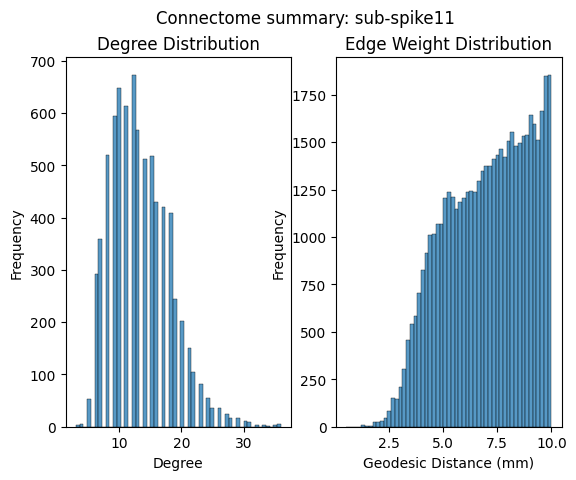

In [5]:
mm.viz.plot_con_summary(geom, sr.sub)

eigenvalues

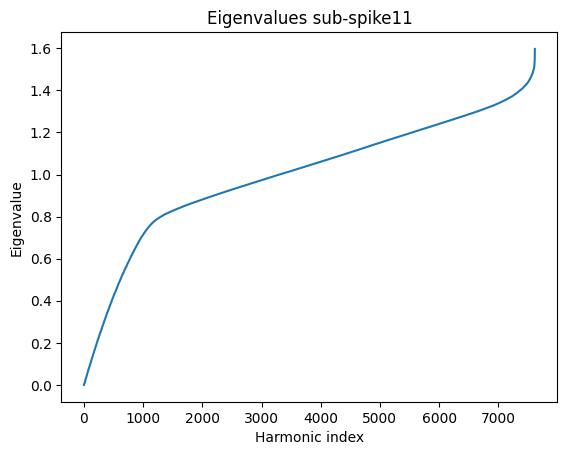

In [6]:
mm.viz.plot_eigval(eigval, sr.sub)

eigenvectors (use command line to open new window and use keyboard arrows as interaction)

In [22]:
%%bash
mindmap-viz eigvec --config "../../config.yml" --subject spike11 --desc geom